# MHEALTH: data exploration and preprocessing
**Md Soad Solaiman · a1978974 · Tasks 1 and 2**

This notebook examines the supplied, modified MHEALTH data and prepares window-level features for later activity classification. The code is kept in small steps, with an explanation before each step. No classifiers are trained here.

**Scope:** the original assignment brief and marking rubric were not supplied with this request. This notebook follows the Task 1–2 requirements discussed in the conversation; formal rubric compliance still needs checking against the brief.

**Run:** put the supplied ZIP in `data/MHEALTHDATASET_MISSING.zip` at the repository root, then run all cells from the top. Start Jupyter from the repository root or use `run_notebooks.py`. Install packages listed in `requirements.txt` first. The notebook reads the ZIP directly and does not change the raw files. Regenerated plots are written to `results/generated_figures/`; the final `figures/` deliverables are never overwritten.

In [1]:
from pathlib import Path
from zipfile import ZipFile
import hashlib
import json
import re
import platform
from io import BytesIO
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

REPO_ROOT = Path.cwd().resolve()
if REPO_ROOT.name == 'notebooks':
    REPO_ROOT = REPO_ROOT.parent
DATA_PATH = REPO_ROOT / 'data' / 'MHEALTHDATASET_MISSING.zip'
RESULTS = REPO_ROOT / 'results'
GENERATED_FIGURES = RESULTS / 'generated_figures'
RESULTS.mkdir(exist_ok=True)
GENERATED_FIGURES.mkdir(parents=True, exist_ok=True)
assert DATA_PATH.exists(), 'Place the supplied ZIP in data/MHEALTHDATASET_MISSING.zip'

SEED = 42
FS = 50  # Documented original sampling rate; no timestamps are supplied.
np.random.seed(SEED)
sns.set_theme(style='whitegrid', context='notebook', font_scale=1.0)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 300,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titleweight': 'bold', 'font.family': 'DejaVu Sans'})
BLUE, ORANGE, GREEN = '#0072B2', '#D55E00', '#009E73'

def save_plot(fig, name):
    buffer = BytesIO()
    fig.savefig(buffer, format='png', bbox_inches='tight')
    (GENERATED_FIGURES / f'{name}.png').write_bytes(buffer.getvalue())
    fig.savefig(GENERATED_FIGURES / f'{name}.svg', bbox_inches='tight')
    plt.show()
    plt.close(fig)

## Task 1 — Understand the data
### 1.1 What the columns mean
The original MHEALTH documentation describes three wearable devices: chest, left ankle and right wrist/lower arm. A **source** is a physical device; a **modality** is a measurement type. The channels cover acceleration, angular velocity, magnetic field and ECG. Two ECG leads do not represent two separate wearable devices.

The column order and activity names below follow the [UCI MHEALTH documentation](https://archive.ics.uci.edu/dataset/319/mhealth+dataset), DOI [10.24432/C5TW22](https://doi.org/10.24432/C5TW22). Its repeated “Column 13” in the ankle magnetometer description is treated as a numbering typo: the X/Y/Z sequence occupies columns 12–14. Labels and dimensions are checked against the uploaded files.

UCI reports 50 Hz. Here, row index is the available ordering information; seconds are derived using that documented rate. We cannot confirm preserved timing, removed rows or uninterrupted recording from these files alone. The original dataset is documented as having no missing values; missingness below is measured in this teaching adaptation. Its cause is not provided.

In [2]:
channel_rows = []
for source, modality, axes, unit in [
    ('chest', 'acc', 'xyz', 'm/s²'),
    ('chest', 'ecg', ['1', '2'], 'mV'),
    ('ankle', 'acc', 'xyz', 'm/s²'),
    ('ankle', 'gyro', 'xyz', 'documented deg/s'),
    ('ankle', 'mag', 'xyz', 'local units'),
    ('wrist', 'acc', 'xyz', 'm/s²'),
    ('wrist', 'gyro', 'xyz', 'documented deg/s'),
    ('wrist', 'mag', 'xyz', 'local units')]:
    for axis in axes:
        channel_rows.append({'channel': f'{source}_{modality}_{axis}',
                             'source': source, 'modality': modality, 'unit': unit})
channels = pd.DataFrame(channel_rows)
channels.insert(0, 'file_column', np.arange(1, 24))
SENSORS = channels['channel'].tolist()
ACTIVITIES = {
    0: 'Null activity', 1: 'Standing', 2: 'Sitting', 3: 'Lying down',
    4: 'Walking', 5: 'Climbing stairs', 6: 'Waist bends',
    7: 'Arm elevation', 8: 'Knees bending', 9: 'Cycling',
    10: 'Jogging', 11: 'Running', 12: 'Jump front/back'}
channels.to_csv(RESULTS / 'channel_dictionary.csv', index=False)
display(channels.groupby(['source', 'modality'], sort=False).agg(
    channels=('channel', 'count'), unit=('unit', 'first')).reset_index())

,source,modality,channels,unit
0,chest,acc,3,m/s²
1,chest,ecg,2,mV
2,ankle,acc,3,m/s²
3,ankle,gyro,3,documented deg/s
4,ankle,mag,3,local units
5,wrist,acc,3,m/s²
6,wrist,gyro,3,documented deg/s
7,wrist,mag,3,local units


In [3]:
frames, file_audit = [], []
with ZipFile(DATA_PATH) as archive:
    names = [name for name in archive.namelist()
             if re.search(r'(^|/)mHealth_subject\d+\.log$', name)
             and not name.startswith('__MACOSX/')]
    names.sort(key=lambda name: int(re.search(r'subject(\d+)', name).group(1)))
    assert len(names) == 10, 'Unexpected number of participant files'
    for name in names:
        participant = int(re.search(r'subject(\d+)', name).group(1))
        frame = pd.read_csv(archive.open(name), sep=r'\s+', header=None)
        assert frame.shape[1] == 24, f'Unexpected columns in {name}'
        frame.columns = SENSORS + ['activity']
        assert frame['activity'].notna().all()
        assert frame['activity'].isin(ACTIVITIES).all()
        assert np.isinf(frame[SENSORS].to_numpy()).sum() == 0
        frame['activity'] = frame['activity'].astype(int)
        frame['participant'] = participant
        frame['sample'] = np.arange(len(frame))
        frame['time_s'] = frame['sample'] / FS
        frame['segment'] = frame['activity'].ne(frame['activity'].shift()).cumsum()
        file_audit.append({'participant': participant, 'rows': len(frame),
                           'missing_cells': int(frame[SENSORS].isna().sum().sum())})
        frames.append(frame)
data = pd.concat(frames, ignore_index=True)
assert not data.duplicated(['participant', 'sample']).any()
assert data['participant'].nunique() == 10
file_audit = pd.DataFrame(file_audit)
file_audit.to_csv(RESULTS / 'file_audit.csv', index=False)
data[SENSORS].describe().T.to_csv(RESULTS / 'sensor_descriptive_statistics.csv')
segments = data.groupby(['participant', 'segment'], sort=False).agg(
    activity=('activity', 'first'), start_sample=('sample', 'min'),
    end_sample=('sample', 'max'), samples=('sample', 'size')).reset_index()
segments.to_csv(RESULTS / 'segment_summary.csv', index=False)
missing_pct = data[SENSORS].isna().mean().mean() * 100
print(f'{len(data):,} rows | {data.participant.nunique()} participants | '
      f'{data.activity.nunique()} labels | {len(SENSORS)} measurement channels')
print(f'Missing sensor cells: {missing_pct:.2f}%')
print(f'Label-0 rows: {(data.activity == 0).sum():,}')
display(file_audit)

343,195 rows | 10 participants | 12 labels | 23 measurement channels
Missing sensor cells: 7.80%
Label-0 rows: 0


,participant,rows,missing_cells
0,1,35174,62722
1,2,35532,63760
2,3,35380,63824
3,4,35328,63702
4,5,33947,60709
5,6,32205,57726
6,7,34253,61401
7,8,33332,59452
8,9,34354,61845
9,10,33690,60507


### 1.2 Activity coverage
Counts describe the supplied files, not the original full recordings. The heatmap checks whether all participants contribute all activities. The bar chart shows class imbalance. Repeated sensor rows are not removed: repeated readings can be valid, and deleting rows would change timing.

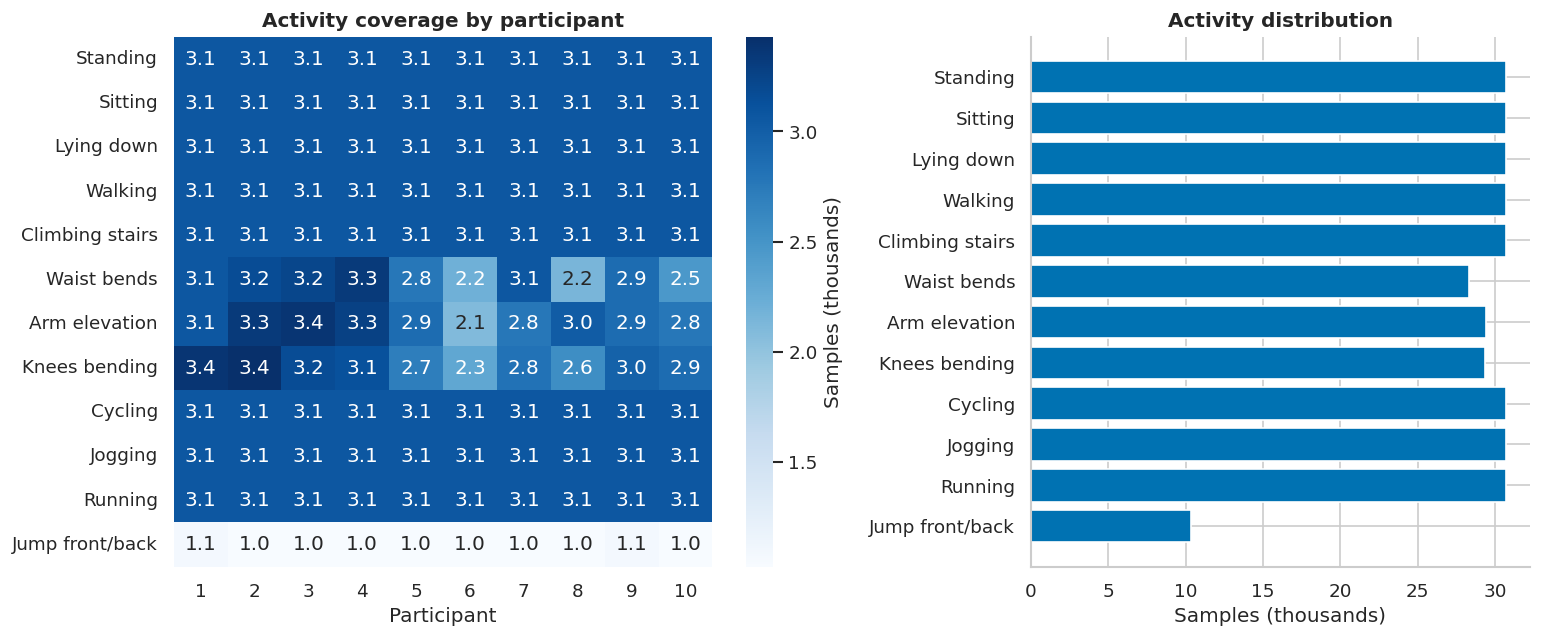

**Finding:** all 10 participants contain all 12 observed activities. Jump front/back has the fewest samples (10,342); the largest class has 30,720. Later evaluation should therefore include macro metrics, not accuracy alone.

In [4]:
coverage = pd.crosstab(data['activity'], data['participant']).reindex(sorted(data.activity.unique()))
coverage.to_csv(RESULTS / 'activity_participant_counts.csv')
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), gridspec_kw={'width_ratios': [1.35, 1]})
sns.heatmap(coverage / 1000, ax=axes[0], cmap='Blues', annot=True, fmt='.1f',
            yticklabels=[ACTIVITIES[i] for i in coverage.index],
            cbar_kws={'label': 'Samples (thousands)'})
axes[0].set(title='Activity coverage by participant', xlabel='Participant', ylabel='')
counts = coverage.sum(axis=1)
axes[1].barh([ACTIVITIES[i] for i in counts.index], counts.values / 1000, color=BLUE)
axes[1].invert_yaxis()
axes[1].set(title='Activity distribution', xlabel='Samples (thousands)', ylabel='')
fig.tight_layout()
save_plot(fig, '01_activity_coverage')
least = counts.idxmin()
display(Markdown(f'**Finding:** all {coverage.shape[1]} participants contain all '
                 f'{coverage.shape[0]} observed activities. {ACTIVITIES[least]} has the fewest '
                 f'samples ({counts.min():,}); the largest class has {counts.max():,}. '
                 'Later evaluation should therefore include macro metrics, not accuracy alone.'))

### 1.3 Sensor patterns across activities
For an interpretable example, compare chest acceleration magnitude for four activities. A magnitude is calculated only where all three acceleration axes are observed. We summarise each participant separately so one participant does not dominate the plot. These descriptive patterns are not a classification result.

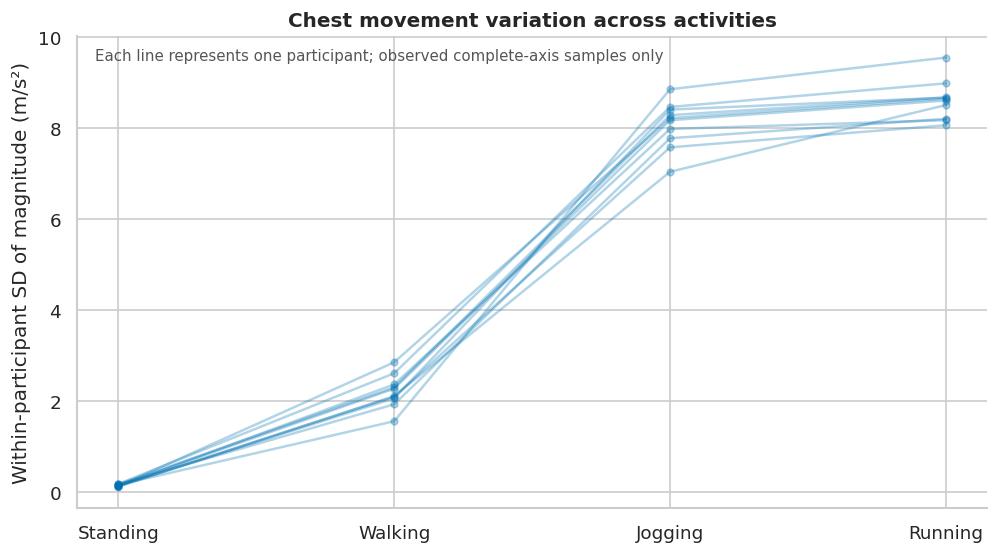

,mean,std
activity,,
Standing,9.764,0.146
Walking,9.900,2.195
Jogging,11.128,8.195
Running,11.712,8.625


**Interpretation:** differences in movement variation motivate window-level spread features. Variation between participant lines motivates participant-independent testing. Missing samples are excluded from this descriptive calculation; their unknown mechanism may affect the summaries.

In [5]:
example = data.loc[data.activity.isin([1, 4, 10, 11]),
                   ['participant', 'activity', 'chest_acc_x', 'chest_acc_y', 'chest_acc_z']].copy()
axes_values = example[['chest_acc_x', 'chest_acc_y', 'chest_acc_z']]
example['magnitude'] = np.sqrt(axes_values.pow(2).sum(axis=1, min_count=3))
motion = example.groupby(['participant', 'activity'])['magnitude'].agg(['mean', 'std']).reset_index()
motion.to_csv(RESULTS / 'chest_motion_summary.csv', index=False)
fig, ax = plt.subplots(figsize=(8.5, 4.8))
for participant, group in motion.groupby('participant'):
    ax.plot(range(4), group.sort_values('activity')['std'], color=BLUE, alpha=.30, marker='o', markersize=4)
ax.set(xticks=range(4), xticklabels=[ACTIVITIES[i] for i in [1, 4, 10, 11]],
       ylabel='Within-participant SD of magnitude (m/s²)',
       title='Chest movement variation across activities')
ax.text(0.02, 0.95, 'Each line represents one participant; observed complete-axis samples only',
        transform=ax.transAxes, fontsize=9, color='#555555')
fig.tight_layout()
save_plot(fig, '02_chest_movement')
display(motion.groupby('activity')[['mean', 'std']].median().rename(index=ACTIVITIES).round(3))
display(Markdown('**Interpretation:** differences in movement variation motivate window-level '
                 'spread features. Variation between participant lines motivates participant-independent '
                 'testing. Missing samples are excluded from this descriptive calculation; their '
                 'unknown mechanism may affect the summaries.'))

## Task 2 — Missing data and preprocessing
### 2.1 Measure missingness before filling anything
We inspect missingness by channel, participant and activity, and measure consecutive missing runs within each participant/activity segment. A similar overall percentage does not prove that missingness is random. We cannot establish MCAR, MAR or MNAR from these summaries.

Complete raw rows across all 23 channels: 15.13%
Longest missing run: 7 samples
Missing runs of at most 5 samples: 99.9978%
Channel missingness range: 1.13%–14.67%


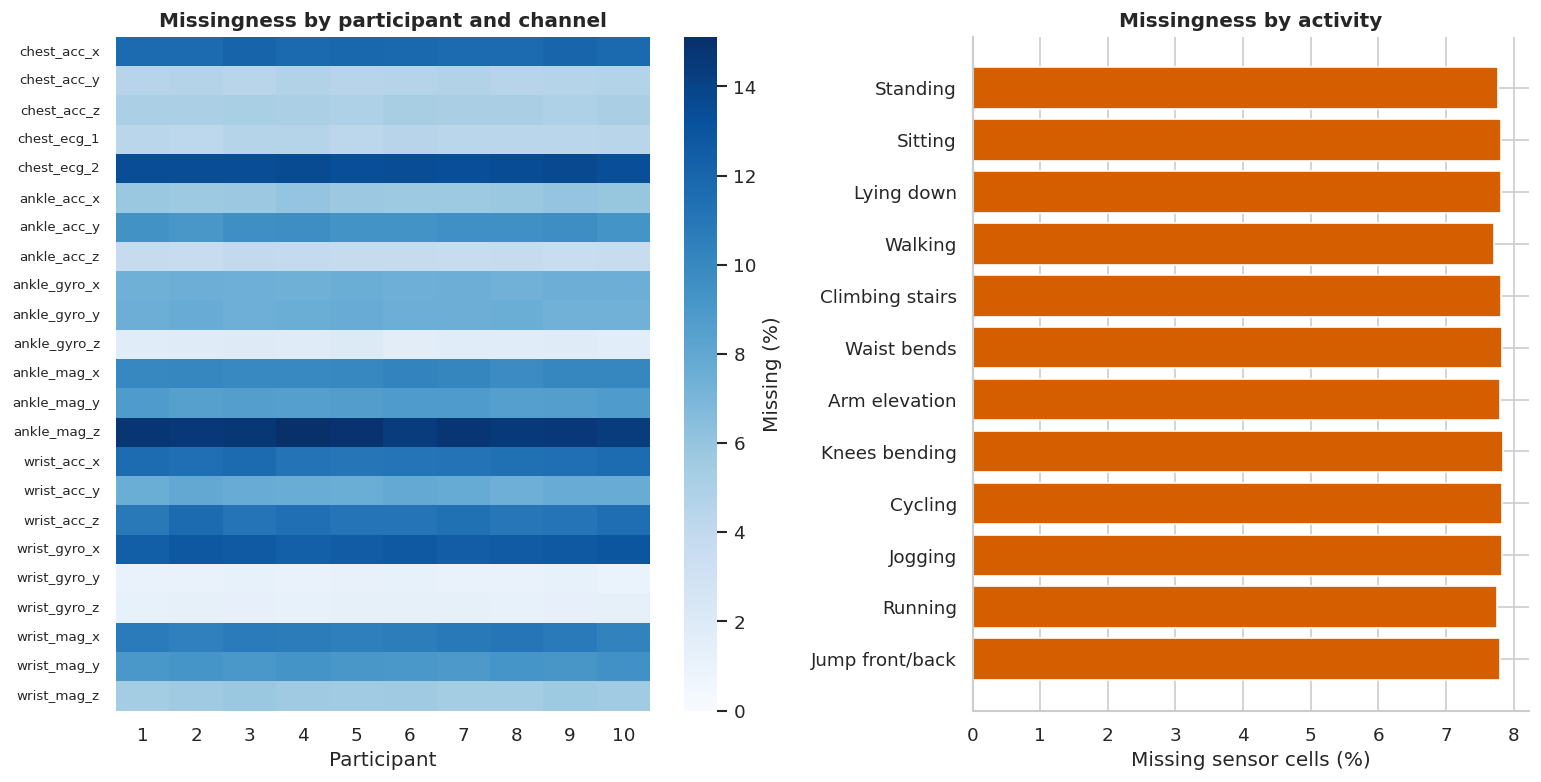

,length,runs,edge_runs,missing_cells
0,1,503127,394,503127
1,2,47483,37,94966
2,3,5016,1,15048
3,4,542,0,2168
4,5,53,0,265
5,6,10,0,60
6,7,2,0,14


**Finding:** ankle_mag_z has the highest missingness (14.67%), while wrist_gyro_y has the lowest (1.13%). Missingness therefore differs substantially by channel. 12 runs exceed the interpolation limit. Dropping every incomplete raw row would discard most of the recording; short-gap filling preserves the sampling grid while retaining explicit rejection rules.

In [6]:
mask = data[SENSORS].isna()
by_channel = mask.mean().mul(100).rename('missing_pct')
by_participant = mask.groupby(data.participant).mean().mul(100)
by_activity = mask.groupby(data.activity).mean().mul(100)
by_channel.to_csv(RESULTS / 'missingness_by_channel.csv')
by_participant.to_csv(RESULTS / 'missingness_by_participant.csv')
by_activity.to_csv(RESULTS / 'missingness_by_activity.csv')

def missing_runs(values):
    missing = np.isnan(np.asarray(values, dtype=float))
    edges = np.diff(np.r_[False, missing, False].astype(int))
    return list(zip(np.flatnonzero(edges == 1), np.flatnonzero(edges == -1)))

run_rows = []
for (participant, segment), group in data.groupby(['participant', 'segment'], sort=False):
    for channel in SENSORS:
        for start, stop in missing_runs(group[channel].to_numpy()):
            run_rows.append({'participant': participant, 'segment': segment,
                             'activity': int(group.activity.iloc[0]), 'channel': channel,
                             'length': stop - start,
                             'edge': start == 0 or stop == len(group)})
runs = pd.DataFrame(run_rows)
run_summary = runs.groupby('length').agg(runs=('length', 'size'), edge_runs=('edge', 'sum')).reset_index()
run_summary['missing_cells'] = run_summary['length'] * run_summary['runs']
run_summary.to_csv(RESULTS / 'missing_run_summary.csv', index=False)
fig, axes = plt.subplots(1, 2, figsize=(13, 6.7), gridspec_kw={'width_ratios': [1.2, 1]})
sns.heatmap(by_participant.T, cmap='Blues', vmin=0, ax=axes[0],
            cbar_kws={'label': 'Missing (%)'})
axes[0].set(title='Missingness by participant and channel', xlabel='Participant', ylabel='')
axes[0].tick_params(axis='y', labelsize=8)
activity_missing = by_activity.mean(axis=1)
axes[1].barh([ACTIVITIES[i] for i in activity_missing.index], activity_missing.values, color=ORANGE)
axes[1].invert_yaxis()
axes[1].set(title='Missingness by activity', xlabel='Missing sensor cells (%)')
fig.tight_layout()
save_plot(fig, '03_missingness')
display(run_summary)
print(f'Complete raw rows across all 23 channels: {(~mask.any(axis=1)).mean():.2%}')
print(f'Longest missing run: {runs.length.max()} samples')
print(f'Missing runs of at most 5 samples: {(runs.length <= 5).mean():.4%}')
print(f'Channel missingness range: {by_channel.min():.2f}%–{by_channel.max():.2f}%')
display(Markdown(f'**Finding:** {by_channel.idxmax()} has the highest missingness '
                 f'({by_channel.max():.2f}%), while {by_channel.idxmin()} has the lowest '
                 f'({by_channel.min():.2f}%). Missingness therefore differs substantially by channel. '
                 f'{int((runs.length > 5).sum())} runs exceed the interpolation limit. '
                 'Dropping every incomplete raw row would discard most of the recording; '
                 'short-gap filling preserves the sampling grid while retaining explicit rejection rules.'))

### 2.2 Preprocessing decisions
- **Labels:** keep activities 1–12. Exclude label 0 if present; none was found in this upload. Never interpolate labels.
- **Short gaps:** linearly interpolate a whole internal missing run only when it is at most **5 samples (0.10 s at the documented rate)**. This conservative rule covers short interruptions without filling extended gaps. It is a declared choice, not a tuned optimum; gap statistics above show its coverage.
- **Boundaries:** never fill across participants or changes in activity label. Leave leading, trailing and longer gaps missing. Contiguity is based on supplied row order; unknown removed intervals cannot be detected.
- **Windows:** use **128 samples (2.56 s)** with a **64-sample stride (50% overlap)**. This provides local movement summaries and multiple observations per activity, without mixing labels. These parameters are fixed before modelling; their optimality is not claimed.
- **Eligibility:** reject a window if any channel originally had more than **20% missing samples**, or if any missing value remains after short-gap interpolation. Use the same all-channel rule for every later baseline/fusion comparison. This conservative common population may discard windows that a smaller sensor subset could use.
- **Tails:** do not pad incomplete windows. Record unused tail samples by segment; no window crosses a segment boundary.

Interpolation uses both sides of a gap, so this is **offline** preprocessing. Known activity labels define boundaries; in live operation those boundaries would not be available. Overlapping windows are dependent, which is why participants—not windows—must be separated during evaluation.

In [7]:
MAX_GAP = 5
WINDOW = 128
STRIDE = 64
MAX_MISSING = 0.20

def fill_short_gaps(values, max_gap=MAX_GAP):
    filled = np.asarray(values, dtype=float).copy()
    for start, stop in missing_runs(filled):
        if stop - start <= max_gap and start > 0 and stop < len(filled):
            filled[start:stop] = np.linspace(filled[start - 1], filled[stop], stop - start + 2)[1:-1]
    return filled

# Check short, long and edge gaps before using the function.
assert np.allclose(fill_short_gaps([0, np.nan, 2]), [0, 1, 2])
assert np.isnan(fill_short_gaps([0] + [np.nan] * 6 + [7])[1:7]).all()
assert np.isnan(fill_short_gaps([np.nan, 1, np.nan])[[0, 2]]).all()

clean = data.copy()
for _, group in data.groupby(['participant', 'segment'], sort=False):
    for channel in SENSORS:
        clean.loc[group.index, channel] = fill_short_gaps(group[channel].to_numpy())
assert np.array_equal(clean['activity'], data['activity'])
assert np.array_equal(clean['participant'], data['participant'])
observed = ~mask.to_numpy()
assert np.array_equal(clean[SENSORS].to_numpy()[observed], data[SENSORS].to_numpy()[observed])
remaining = int(clean[SENSORS].isna().sum().sum())
original_missing = int(mask.sum().sum())
print(f'Missing cells before: {original_missing:,}')
print(f'Filled cells: {original_missing - remaining:,}')
print(f'Missing cells left: {remaining:,}')

Missing cells before: 615,648
Filled cells: 615,103
Missing cells left: 545


### 2.3 Extract simple features
Each retained window becomes one row. For each of the 23 channels we calculate **mean, standard deviation, minimum, maximum, root mean square and interquartile range**: 138 features in total. Mean describes signal level; standard deviation and IQR describe spread; minimum/maximum describe extremes; RMS describes signal amplitude. These are simple time-domain summaries, not clinical ECG measures or estimates of heart rate.

All available channels are prepared, so later sensor selection can use named subsets without repeating preprocessing. This does not yet choose a winning source or train a fusion model. Participant, activity, sample indices and window ID are metadata, kept in a separate file from predictive features.

In [8]:
FEATURES = ['mean', 'std', 'min', 'max', 'rms', 'iqr']
feature_names = [f'{channel}__{stat}' for channel in SENSORS for stat in FEATURES]
feature_rows, metadata_rows, audit_rows, tail_rows = [], [], [], []
for (participant, segment), raw_group in data.groupby(['participant', 'segment'], sort=False):
    activity = int(raw_group.activity.iloc[0])
    if activity == 0:
        continue
    original = raw_group[SENSORS].to_numpy()
    filled = clean.loc[raw_group.index, SENSORS].to_numpy()
    starts = list(range(0, len(raw_group) - WINDOW + 1, STRIDE))
    last_end = starts[-1] + WINDOW if starts else 0
    tail_rows.append({'participant': participant, 'segment': segment, 'activity': activity,
                      'segment_samples': len(raw_group), 'tail_samples': len(raw_group) - last_end})
    for start in starts:
        stop = start + WINDOW
        block = filled[start:stop]
        worst_missing = np.isnan(original[start:stop]).mean(axis=0).max()
        if worst_missing > MAX_MISSING:
            status = 'Too much original missingness'
        elif np.isnan(block).any():
            status = 'Unfilled gap'
        else:
            status = 'Retained'
        start_sample = int(raw_group['sample'].iloc[start])
        window_id = f'p{participant:02d}_s{segment:03d}_r{start_sample:06d}'
        audit_rows.append({'window_id': window_id, 'participant': participant, 'activity': activity,
                           'status': status, 'max_original_missing_fraction': worst_missing})
        if status != 'Retained':
            continue
        stats = np.column_stack([block.mean(axis=0), block.std(axis=0, ddof=0),
                                 block.min(axis=0), block.max(axis=0),
                                 np.sqrt(np.mean(block ** 2, axis=0)),
                                 np.percentile(block, 75, axis=0) - np.percentile(block, 25, axis=0)])
        feature_rows.append(stats.ravel())
        metadata_rows.append({'window_id': window_id, 'participant': participant,
                              'activity': activity, 'segment': segment, 'start_sample': start_sample,
                              'end_sample': int(raw_group['sample'].iloc[stop - 1])})
X = pd.DataFrame(feature_rows, columns=feature_names)
metadata = pd.DataFrame(metadata_rows)
X.index = metadata['window_id']
X.index.name = 'window_id'
window_audit = pd.DataFrame(audit_rows)
tails = pd.DataFrame(tail_rows)
assert len(X) == len(metadata) and len(X) > 0
assert np.isfinite(X.to_numpy()).all()
assert metadata['window_id'].is_unique
assert (metadata.end_sample - metadata.start_sample + 1).eq(WINDOW).all()
assert not set(['activity', 'participant', 'segment', 'sample', 'time_s']).intersection(X.columns)
X.to_csv(RESULTS / 'window_features.csv.gz', compression='gzip')
metadata.to_csv(RESULTS / 'window_metadata.csv', index=False)
window_audit.to_csv(RESULTS / 'window_audit.csv', index=False)
tails.to_csv(RESULTS / 'segment_tails.csv', index=False)
feature_dictionary = channels.merge(pd.DataFrame({'statistic': FEATURES}), how='cross')
feature_dictionary['feature'] = feature_dictionary.channel + '__' + feature_dictionary.statistic
feature_dictionary.to_csv(RESULTS / 'feature_dictionary.csv', index=False)
print(f'Candidate windows: {len(window_audit):,}')
print(f'Retained windows: {len(X):,}; extracted features: {X.shape[1]}')
display(window_audit.status.value_counts().rename('windows').to_frame())

Candidate windows: 5,229
Retained windows: 4,581; extracted features: 138


,windows
status,
Retained,4581
Too much original missingness,474
Unfilled gap,174


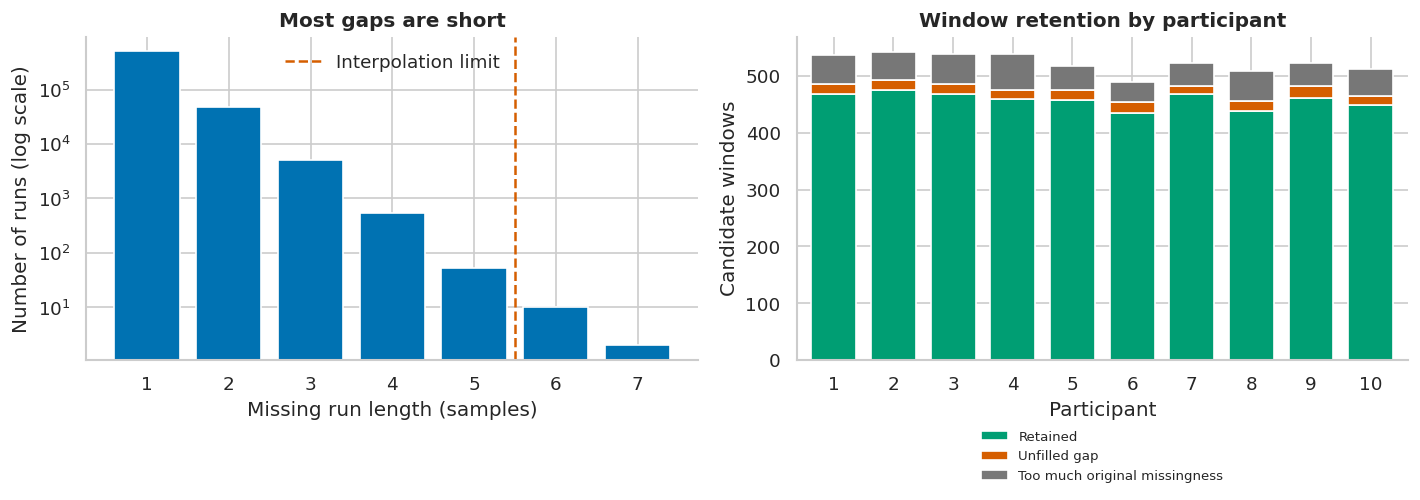

**Outcome:** 4,581 of 5,229 candidate windows were retained (87.6%). All 12 activities remain for each participant. The incomplete tails contain 859 sample positions in total. Window counts overlap and must not be interpreted as independent observations. The saved activity-retention table makes exclusion patterns available for later discussion.

In [9]:
retention = pd.crosstab(window_audit.participant, window_audit.status).reindex(
    columns=['Retained', 'Unfilled gap', 'Too much original missingness'], fill_value=0)
retention.to_csv(RESULTS / 'window_retention_by_participant.csv')
activity_retention = pd.crosstab(window_audit.activity, window_audit.status)
activity_retention.to_csv(RESULTS / 'window_retention_by_activity.csv')
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].bar(run_summary.length, run_summary.runs, color=BLUE)
axes[0].set(yscale='log', xlabel='Missing run length (samples)', ylabel='Number of runs (log scale)',
            title='Most gaps are short')
axes[0].axvline(MAX_GAP + .5, color=ORANGE, linestyle='--', label='Interpolation limit')
axes[0].legend(frameon=False)
retention.plot.bar(stacked=True, ax=axes[1], color=[GREEN, ORANGE, '#777777'], width=.75)
axes[1].set(title='Window retention by participant', xlabel='Participant', ylabel='Candidate windows')
axes[1].tick_params(axis='x', rotation=0)
axes[1].legend(title='', fontsize=8, frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=1)
fig.tight_layout()
save_plot(fig, '04_gaps_and_retention')
retained_by_activity = metadata.activity.value_counts().sort_index()
assert set(retained_by_activity.index) == set(range(1, 13))
assert metadata.groupby('participant').activity.nunique().eq(12).all()
display(Markdown(f'**Outcome:** {len(X):,} of {len(window_audit):,} candidate windows were retained '
                 f'({len(X) / len(window_audit):.1%}). All 12 activities remain for each participant. '
                 f'The incomplete tails contain {tails.tail_samples.sum():,} sample positions in total. '
                 'Window counts overlap and must not be interpreted as independent observations. '
                 'The saved activity-retention table makes exclusion patterns available for later discussion.'))

### 2.4 Prepare participant-independent evaluation
We save a leave-one-participant-out plan for Task 3: the held-out participant is the test fold and all others are training participants. Every baseline and fusion model must use these same window IDs. Overlapping windows from one participant therefore stay on the same side of each split.

No scaling, feature selection or population-level imputation is fitted in Tasks 1–2. Retained features are finite, so residual feature imputation is not needed here. If scaling, imputation or selection is introduced later, it must be fitted inside each training fold using a scikit-learn pipeline. Any tuning must use participant-grouped inner validation on the outer training participants only. The gap/window settings above are fixed choices, not settings selected using test accuracy. Inspecting dataset-wide quality in EDA is disclosed; it does not provide an untouched external validation dataset.

In [10]:
participants = sorted(metadata.participant.unique().tolist())
fold_plan = []
for test_participant in participants:
    train = metadata.participant != test_participant
    test = ~train
    train_people = sorted(metadata.loc[train, 'participant'].unique().tolist())
    assert set(train_people).isdisjoint({test_participant})
    assert set(metadata.loc[train, 'window_id']).isdisjoint(metadata.loc[test, 'window_id'])
    fold_plan.append({'fold': int(test_participant), 'test_participant': int(test_participant),
                      'train_participants': ' '.join(map(str, train_people)),
                      'train_windows': int(train.sum()), 'test_windows': int(test.sum())})
folds = pd.DataFrame(fold_plan)
folds.to_csv(RESULTS / 'participant_folds.csv', index=False)
assert folds.test_windows.sum() == len(metadata)
# Save possible source/modality subsets. No model choice is made here.
feature_groups = {
    'by_source': {source: feature_dictionary.loc[feature_dictionary.source == source, 'feature'].tolist()
                  for source in channels.source.unique()},
    'by_modality': {modality: feature_dictionary.loc[feature_dictionary.modality == modality, 'feature'].tolist()
                    for modality in channels.modality.unique()}}
(RESULTS / 'feature_groups.json').write_text(json.dumps(feature_groups, indent=2))
config = {'sampling_hz_assumed_from_documentation': FS, 'max_internal_gap_samples': MAX_GAP,
          'window_samples': WINDOW, 'stride_samples': STRIDE,
          'max_original_missing_fraction_per_channel': MAX_MISSING,
          'residual_missing_policy': 'reject window', 'label_policy': 'keep 1–12, exclude 0',
          'feature_statistics': FEATURES, 'seed': SEED,
          'archive_sha256': hashlib.sha256(DATA_PATH.read_bytes()).hexdigest(),
          'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__}
(RESULTS / 'preprocessing_config.json').write_text(json.dumps(config, indent=2))
display(folds)
print('Checks passed: finite features, unique windows, boundary-safe windows and disjoint participants.')

Checks passed: finite features, unique windows, boundary-safe windows and disjoint participants.


,fold,test_participant,train_participants,train_windows,test_windows
0,1,1,2 3 4 5 6 7 8 9 10,4112,469
1,2,2,1 3 4 5 6 7 8 9 10,4105,476
2,3,3,1 2 4 5 6 7 8 9 10,4113,468
3,4,4,1 2 3 5 6 7 8 9 10,4122,459
4,5,5,1 2 3 4 6 7 8 9 10,4123,458
5,6,6,1 2 3 4 5 7 8 9 10,4146,435
6,7,7,1 2 3 4 5 6 8 9 10,4113,468
7,8,8,1 2 3 4 5 6 7 9 10,4142,439
8,9,9,1 2 3 4 5 6 7 8 10,4120,461
9,10,10,1 2 3 4 5 6 7 8 9,4133,448


### 2.5 Conclusions and limits
Task 1 establishes the actual activity coverage and missingness of the uploaded adaptation. Task 2 turns ordered sensor measurements into a reproducible, labelled feature table. Features from all three device locations and all four recorded modalities are available for later selection.

Important limits remain: the missingness mechanism is unknown; timestamps are absent; short-gap interpolation can smooth peaks, including ECG peaks; complete-window eligibility may introduce selection bias; and simple statistics do not retain the full waveform. Known activity boundaries and two-sided interpolation make this an offline, annotation-assisted analysis. A participant split controls person overlap, but it does not establish performance in real-world continuous streams.

**Next step (Task 3):** justify selected sensor sources/modalities, then train the unimodal baselines and two fusion approaches using the saved common windows and participant folds. Do not use participant identifiers or activity labels as predictors. No model accuracy can be reported from this notebook because no model has been trained.

### Reference
Banos, O., Garcia, R., & Saez, A. (2014). *MHEALTH* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5TW22 (documentation consulted 22 September 2026). Dataset facts from this source describe the original release; all counts and missingness values above were calculated from the supplied adaptation.